In [5]:
import hist
import gzip
import uproot
import correctionlib
import correctionlib.schemav2 as cs
import matplotlib.pyplot as plt
from pathlib import Path

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb3af449950>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb3af288b90>, text=[])

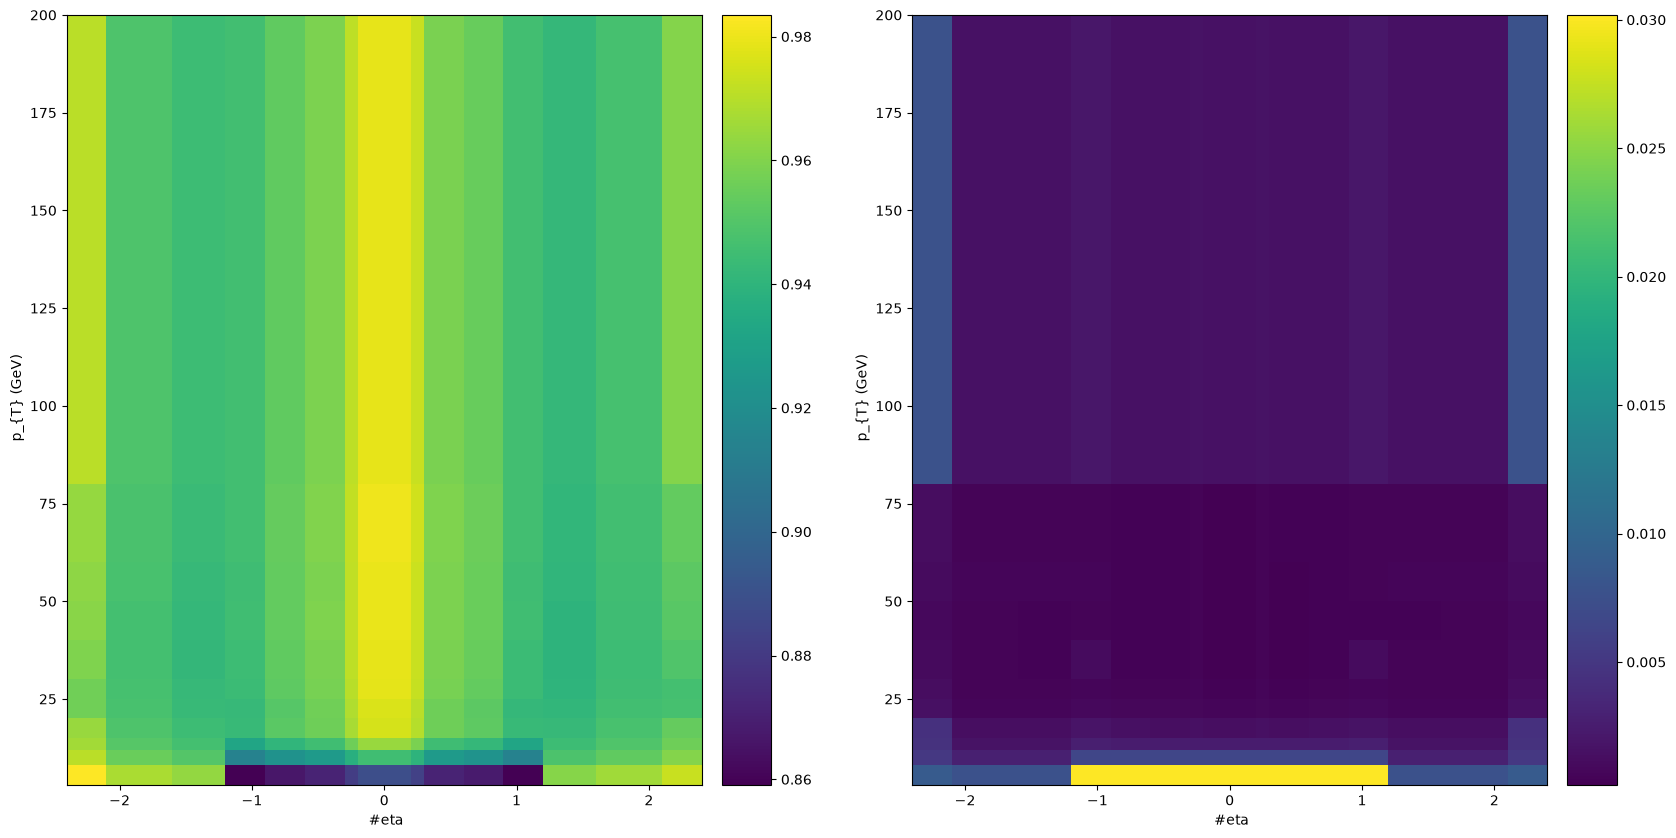

In [6]:
with uproot.open("/afs/cern.ch/user/y/yujil/public/SF2022/final_HZZ_SF_Run3_2022_mupogsysts_newLoose_abseta3_fix_BCD_RMS.root") as root_file:
    sf_2022preEE = root_file["FINAL"].to_hist()
    unc_2022preEE = root_file["ERROR"].to_hist()

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sf_2022preEE.plot2d(ax=ax[0])
unc_2022preEE.plot2d(ax=ax[1])

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb3af1c6fd0>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb3af206210>, text=[])

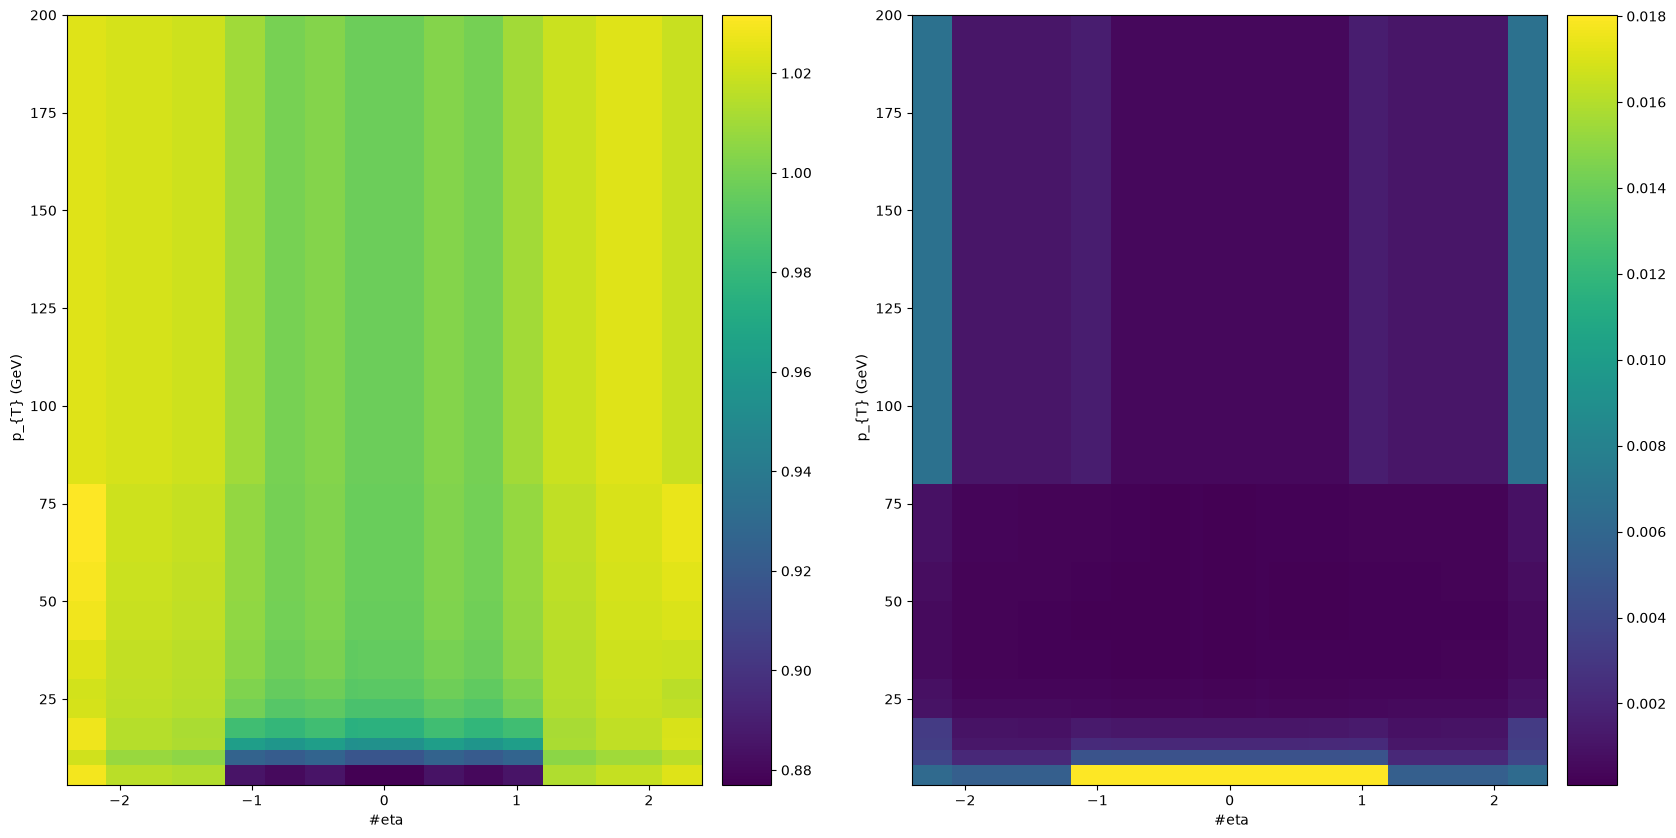

In [7]:
with uproot.open("/afs/cern.ch/user/y/yujil/public/SF2022/final_HZZ_SF_Run3_2022_mupogsysts_newLoose_abseta3_fix_EFG_RMS.root") as root_file:
    sf_2022postEE = root_file["FINAL"].to_hist()
    unc_2022postEE = root_file["ERROR"].to_hist()

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sf_2022postEE.plot2d(ax=ax[0])
unc_2022postEE.plot2d(ax=ax[1])

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb3af14dd10>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb3aef88f50>, text=[])

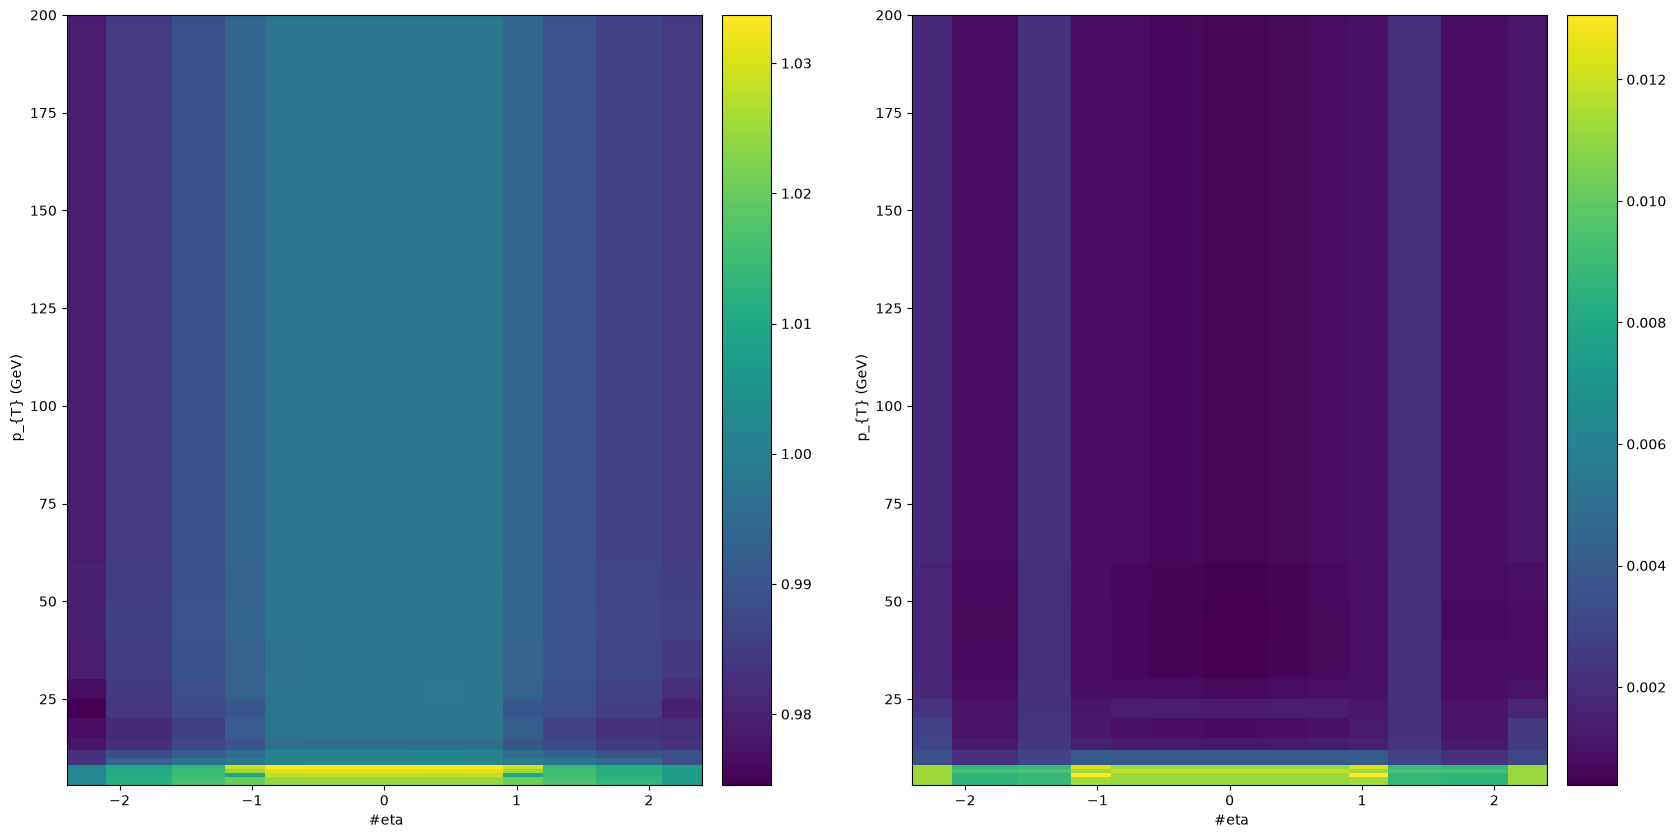

In [8]:
with uproot.open("/afs/cern.ch/user/y/yujil/public/SF2023/final_HZZ_SF_2023C_RMS_mupogsysts.root") as root_file:
    sf_2023preBPix = root_file["FINAL"].to_hist()
    unc_2023preBPix = root_file["ERROR"].to_hist()

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sf_2023preBPix.plot2d(ax=ax[0])
unc_2023preBPix.plot2d(ax=ax[1])

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb3aeeaec10>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb3aeee5e50>, text=[])

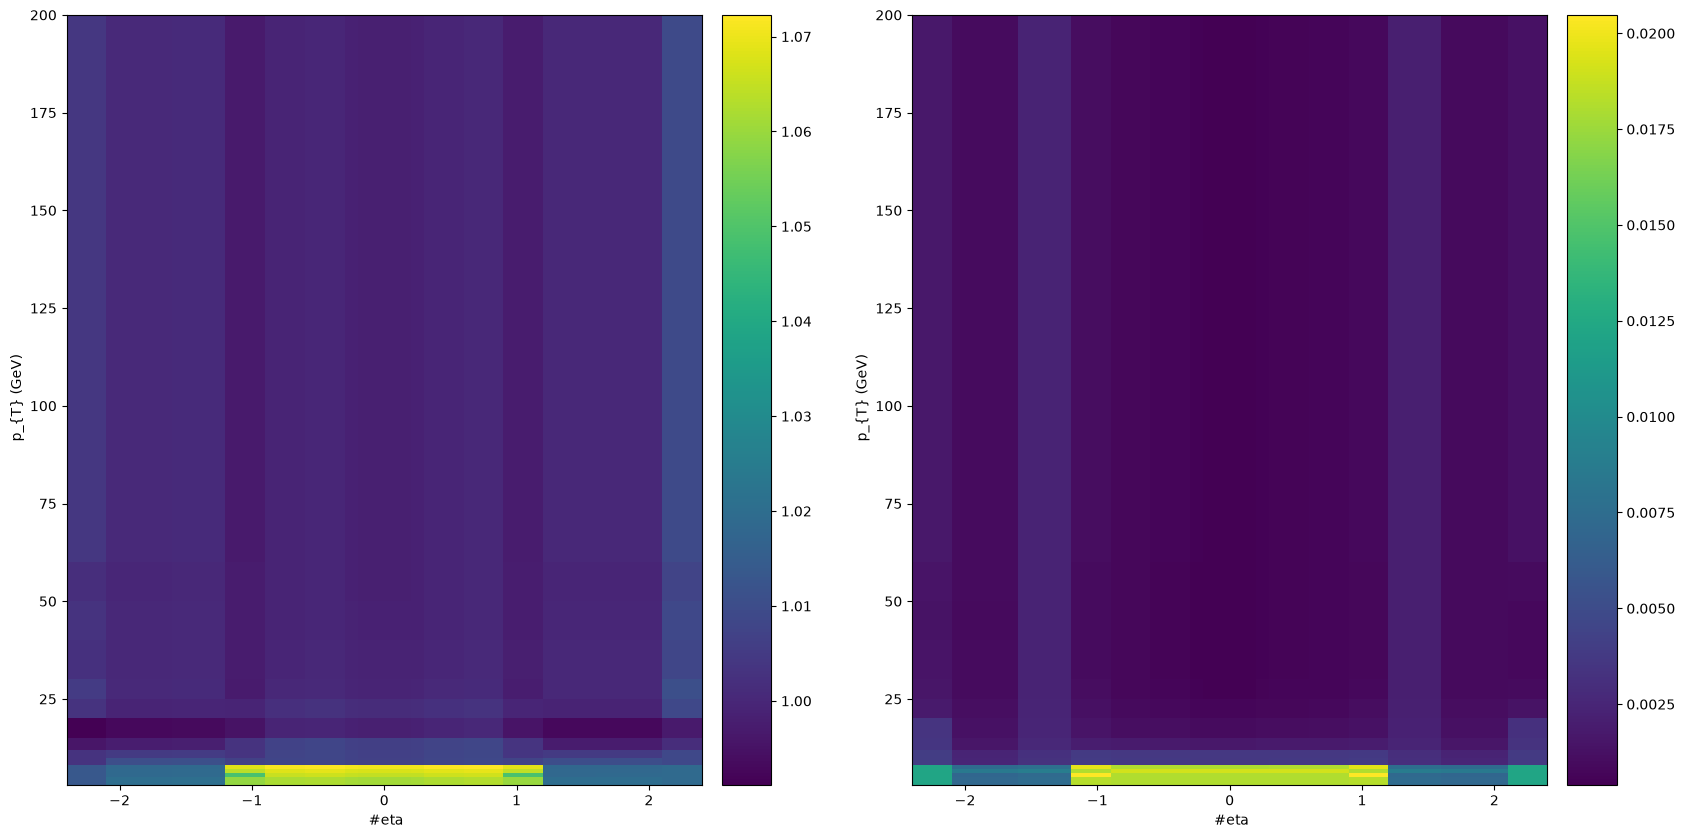

In [9]:
with uproot.open("/afs/cern.ch/user/y/yujil/public/SF2023/final_HZZ_SF_2023D_RMS_mupogsysts.root") as root_file:
    sf_2023postBPix = root_file["FINAL"].to_hist()
    unc_2023postBPix = root_file["ERROR"].to_hist()

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sf_2023postBPix.plot2d(ax=ax[0])
unc_2023postBPix.plot2d(ax=ax[1])

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb3aee31950>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb3aee6cb90>, text=[])

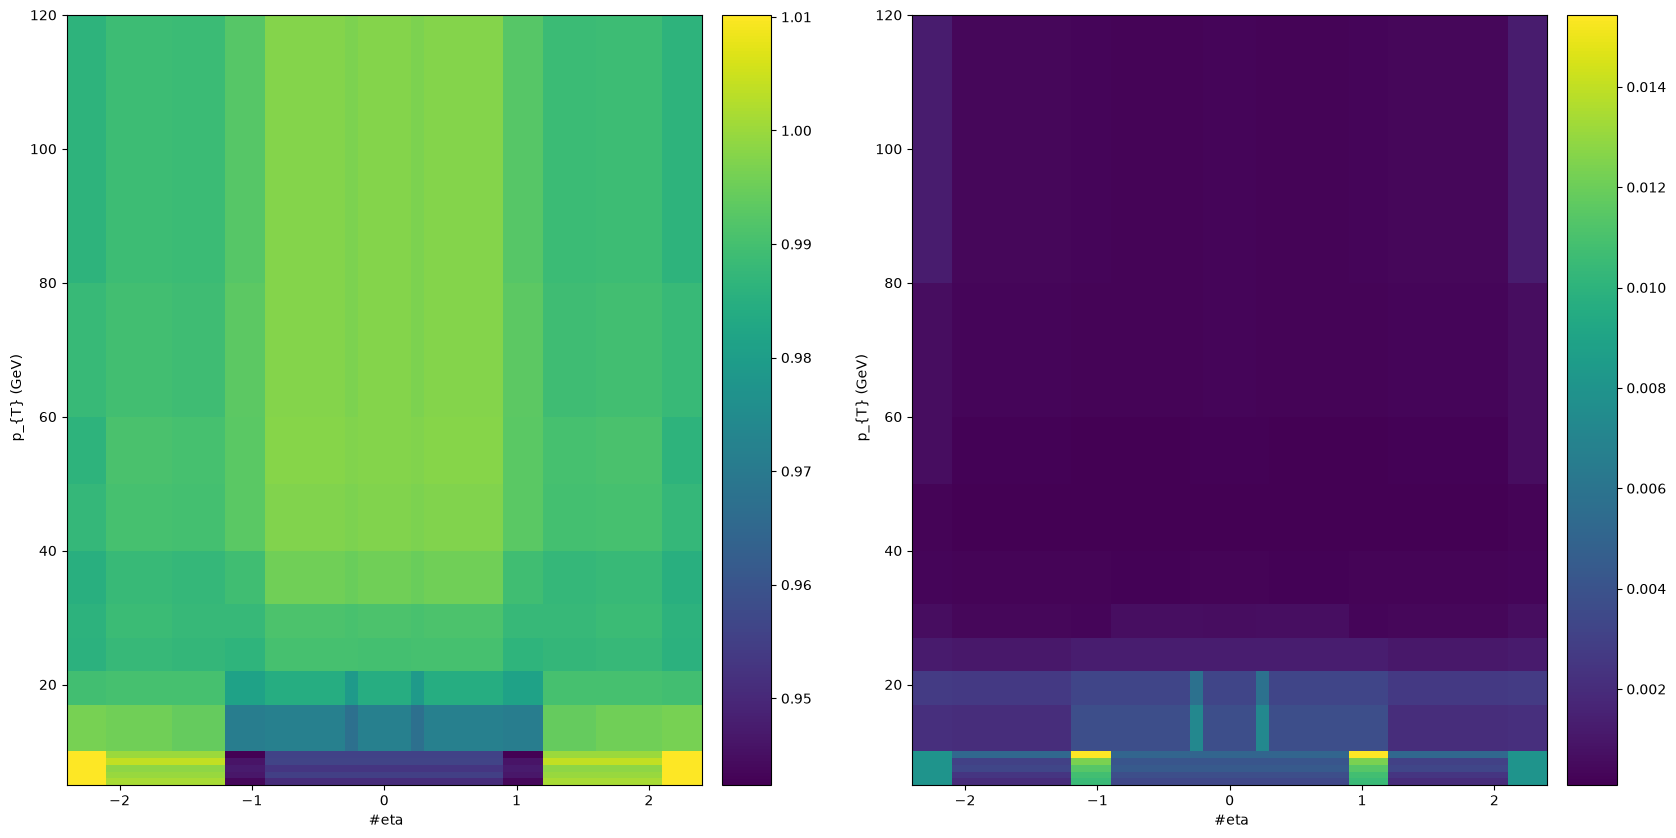

In [10]:
with uproot.open("/afs/cern.ch/user/y/yujil/public/SF2024/SF2024/HZZ_HZZ_SF_2024_RMS_mupogsystsC.root") as root_file:
    sf_2024 = root_file["FINAL"].to_hist()
    unc_2024 = root_file["ERROR"].to_hist()

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sf_2024.plot2d(ax=ax[0])
unc_2024.plot2d(ax=ax[1])

In [12]:
axis_names = ["eta", "pt"]

def hist_to_multibinning(h):
    """Convert a 2D Hist object into a correctionlib MultiBinning node."""
    edges = [axis.edges.tolist() for axis in h.axes]
    return cs.MultiBinning(
        nodetype="multibinning",
        inputs=axis_names,
        edges=edges,
        content=h.values(flow=False).ravel(order="C").tolist(),
        flow="clamp",
    )


def create_muon_sf_correction(sf_hist, unc_hist, campaign):
    """Create a correction containing nominal SFs and uncertainties."""

    # Check that both histograms have compatible axes.
    assert [axis.name for axis in sf_hist.axes] == [
        axis.name for axis in unc_hist.axes
    ]

    assert all(
        (sf_axis.edges == unc_axis.edges).all()
        for sf_axis, unc_axis in zip(sf_hist.axes, unc_hist.axes)
    )

    # Convert both histograms.
    nominal = hist_to_multibinning(sf_hist)
    uncertainty = hist_to_multibinning(unc_hist)

    # Define the correction.
    correction = cs.Correction(
        name=f"HZZ_muon_id_sf",
        description=f"{campaign} HZZ muon ID scale factors and uncertainties",
        version=1,
        inputs=[
            cs.Variable(
                name="variation",
                type="string",
                description="nominal or error",
            ),
            *[
                cs.Variable(name=axis, type="real")
                for axis in axis_names
            ],
        ],
        output=cs.Variable(
            name="weight",
            type="real",
            description="Muon ID scale factor or absolute uncertainty",
        ),
        data=cs.Category(
            nodetype="category",
            input="variation",
            content=[
                cs.CategoryItem(key="nominal", value=nominal),
                cs.CategoryItem(key="error", value=uncertainty),
            ],
        ),
    )

    return cs.CorrectionSet(
        schema_version=2,
        corrections=[correction],
    )


# Define the histograms for each campaign.
campaigns = {
    "2022preEE": (sf_2022preEE, unc_2022preEE),
    "2022postEE": (sf_2022postEE, unc_2022postEE),
    "2023preBPix": (sf_2023preBPix, unc_2023preBPix),
    "2023postBPix": (sf_2023postBPix, unc_2023postBPix),
    "2024": (sf_2024, unc_2024),
}

# Generate one JSON file per campaign.
for campaign, (sf_hist, unc_hist) in campaigns.items():

    cset = create_muon_sf_correction(
        sf_hist,
        unc_hist,
        campaign,
    )

    output_dir = Path.cwd().parent / "analysis/data/hzz_lepton_sf"
    if not output_dir.exists():
        output_dir.mkdir(parents=True)
    
    output_file = output_dir / f"muon_sf_{campaign}.json.gz"

    with gzip.open(output_file, "wt", encoding="utf-8") as f:
        f.write(cset.model_dump_json(exclude_unset=True, indent=2))

    print(f"Saved: {output_file}")

Saved: /afs/cern.ch/user/d/daocampo/public/higgscharm/analysis/data/hzz_lepton_sf/muon_sf_2022preEE.json.gz
Saved: /afs/cern.ch/user/d/daocampo/public/higgscharm/analysis/data/hzz_lepton_sf/muon_sf_2022postEE.json.gz
Saved: /afs/cern.ch/user/d/daocampo/public/higgscharm/analysis/data/hzz_lepton_sf/muon_sf_2023preBPix.json.gz
Saved: /afs/cern.ch/user/d/daocampo/public/higgscharm/analysis/data/hzz_lepton_sf/muon_sf_2023postBPix.json.gz
Saved: /afs/cern.ch/user/d/daocampo/public/higgscharm/analysis/data/hzz_lepton_sf/muon_sf_2024.json.gz
